# Apply Simple Hill Climbing to a Maze Problem

This notebook demonstrates how hill climbing local search behaves applies to the L-Maze problem.

## Setup

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("L_maze.txt", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")
download("maze_helper.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")

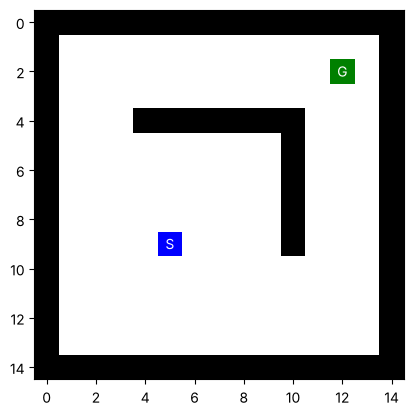

In [2]:
import numpy as np
import maze_helper as mh

f = open("L_maze.txt", "r")

maze_str = f.read()
maze = mh.parse_maze(maze_str)

mh.show_maze(maze)

## Search Helper

We need to define an expand function that will produce the neighbors for local search.

In [3]:
DIR2POS = {
    'N' : (-1, 0),
    'E' : ( 0, 1),
    'S' : ( 1, 0),
    'W' : ( 0,-1)
}

ORDER = None
RANDOMIZATION = None
DIRS = None 

# The order matters if RANDOMIZATION = False
# Note that: DFS works takes elements from the frontier in reverse order!
def set_order(order = "NESW", random = False, verbose = True):
    global RANDOMIZATION, DIR2POS, ORDER, DIRS
    
    RANDOMIZATION = random
    ORDER = [pos for pos in order]
    DIRS = [DIR2POS[dir] for dir in ORDER]
    
    if verbose:
        if RANDOMIZATION:
            print("Directions are checked at every step in random order.")
        else:
            print(f"Directions are checked in the order {ORDER}")
        
set_order("NESW", verbose = True)

Directions are checked in the order ['N', 'E', 'S', 'W']


In [4]:
def expand(maze, pos):
    """find available directions as a list of lists with elements [dir, (pos)]."""
    global RANDOMIZATION, DIRS, ORDER
       
    available = [[dir, pos] for dir, pos in zip(ORDER, np.add(pos, DIRS)) if mh.look(maze, pos) != "X"]
    if RANDOMIZATION: np.random.shuffle(available)
        
    return available

# Hill Climbing

We use Manhattan distance to the goal as the objective function (minimization).

In [5]:
# Manhattan distance h(n)
def manhattan(pos1, pos2):
    """returns the Manhattan distance between two positions"""
    return(np.sum(np.abs(np.subtract(pos1, pos2))))
    
print(manhattan([0,0], [1,1]))

2


In [6]:
def local_search(maze, vis = False, animation = False, verbose = False):
    if animation:
        maze_anim = []
    else:
        maze_anim = None
    
    # Local search starts here
    start_pos = mh.find_pos(maze, "S")
    goal_pos = mh.find_pos(maze, "G")

    current = start_pos
    current_obj = manhattan(current, goal_pos)

    while True:
        # find best neighbor
        neighbors = [n[1] for n in expand(maze, current)]
        obj = [manhattan(n, goal_pos) for n in neighbors]
        best_obj = min(obj)
        best_neighbor = neighbors[obj.index(best_obj)]

        if verbose:
            print("Current state:", current, "with obj", current_obj)
            print("Evaluating neighbors:\t", neighbors)
            print("Obj:\t\t\t", obj)


        # move there if it is an improvement or stop
        if best_obj < current_obj:
            current = best_neighbor
            current_obj = best_obj
            if verbose:
                print("Moving to:", current, "\n")
        else:
            if verbose:
                print("No better state in the neighborhood! Stopping.\n")
            break

        if animation:
            maze2 = maze.copy()
            maze2[current[0], current[1]] = "P"
            maze_anim.append(maze2)


    return { "solution" : current, "path" : None, "reached" : None, "maze_anim" : maze_anim }

## Run the Algorithm

Hàm mục tiêu: $h(n) = |r_n - r_G| + |c_n - c_G|$ (khoảng cách Manhattan tới đích G, **giảm h là cải thiện**). Với 4 hướng N, E, S, W thì `expand(maze, pos)` trả về các ô kề không phải tường `X`. Thuật toán `local_search` là **simple/steepest hill climbing**: nhìn các ô kề, đi tới ô có h nhỏ nhất, và dừng khi không ô nào có h nhỏ hơn h hiện tại. Nó **không nhớ đường đi**, chỉ giữ trạng thái hiện tại, nên bộ nhớ O(1).

## Run the Algorithm

In [7]:
%time result = local_search(maze, animation = True, verbose = True)
print("Vị trí dừng (result['solution']):", result["solution"])

ani = mh.animate_maze(result)

Current state: (np.int64(9), np.int64(5)) with obj 14
Evaluating neighbors:	 [array([8, 5]), array([9, 6]), array([10,  5]), array([9, 4])]
Obj:			 [np.int64(13), np.int64(13), np.int64(15), np.int64(15)]
Moving to: [8 5] 

Current state: [8 5] with obj 13
Evaluating neighbors:	 [array([7, 5]), array([8, 6]), array([9, 5]), array([8, 4])]
Obj:			 [np.int64(12), np.int64(12), np.int64(14), np.int64(14)]
Moving to: [7 5] 

Current state: [7 5] with obj 12
Evaluating neighbors:	 [array([6, 5]), array([7, 6]), array([8, 5]), array([7, 4])]
Obj:			 [np.int64(11), np.int64(11), np.int64(13), np.int64(13)]
Moving to: [6 5] 

Current state: [6 5] with obj 11
Evaluating neighbors:	 [array([5, 5]), array([6, 6]), array([7, 5]), array([6, 4])]
Obj:			 [np.int64(10), np.int64(10), np.int64(12), np.int64(12)]
Moving to: [5 5] 

Current state: [5 5] with obj 10
Evaluating neighbors:	 [array([5, 6]), array([6, 5]), array([5, 4])]
Obj:			 [np.int64(9), np.int64(11), np.int64(11)]
Moving to: [5 6] 

Cu

In [8]:
# hiển thị animation trong notebook (nếu không thấy animation thì xem hình tĩnh bên dưới)
from IPython.display import HTML
HTML(ani.to_jshtml())

In [9]:
# Ghi nhận kết quả: vị trí dừng so với đích G
start, goal = tuple(int(x) for x in mh.find_pos(maze, "S")), tuple(int(x) for x in mh.find_pos(maze, "G"))
stop = tuple(int(x) for x in result["solution"])
print("Start S:", start, "| h(S) =", manhattan(start, goal))
print("Goal  G:", goal)
print("Dừng tại:", stop, "| h =", manhattan(stop, goal), "| đã đến đích?", stop == goal)

Start S: (9, 5) | h(S) = 14
Goal  G: (2, 12)
Dừng tại: (5, 9) | h = 6 | đã đến đích? False


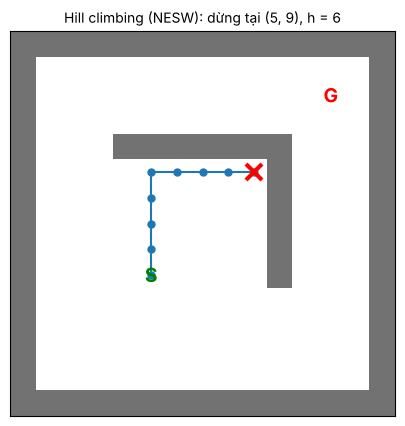

In [10]:
# Hình tĩnh: vẽ đường đi của hill climbing trên mê cung
import matplotlib.pyplot as plt

def local_search_trace(maze):
    """Giống local_search nhưng trả về cả đường đi (list các ô). Dùng ORDER/RANDOMIZATION hiện hành."""
    cur = tuple(int(x) for x in mh.find_pos(maze, "S")); goal = mh.find_pos(maze, "G")
    path = [cur]; cur_obj = manhattan(cur, goal)
    while True:
        nbrs = [tuple(int(x) for x in n[1]) for n in expand(maze, cur)]
        obj = [manhattan(n, goal) for n in nbrs]
        if min(obj) < cur_obj:
            cur = nbrs[obj.index(min(obj))]; cur_obj = min(obj); path.append(cur)
        else:
            return path

def plot_maze_path(maze, path, ax, title=""):
    grid = np.array([[1 if c == "X" else 0 for c in row] for row in maze])
    ax.imshow(grid, cmap="Greys", vmin=0, vmax=1.6)
    ys, xs = zip(*path); ax.plot(xs, ys, "o-", color="tab:blue", ms=5)
    s, g = mh.find_pos(maze, "S"), mh.find_pos(maze, "G")
    ax.text(s[1], s[0], "S", color="green", ha="center", va="center", fontsize=14, fontweight="bold")
    ax.text(g[1], g[0], "G", color="red", ha="center", va="center", fontsize=14, fontweight="bold")
    ax.plot(path[-1][1], path[-1][0], "x", color="red", ms=12, mew=3)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=10)

set_order("NESW", verbose = False)
path = local_search_trace(maze)
fig, ax = plt.subplots(figsize=(5, 5)); plot_maze_path(maze, path, ax, f"Hill climbing (NESW): dừng tại {path[-1]}, h = {manhattan(path[-1], goal)}")
plt.show()

**Kết quả và giải thích vì sao dừng mà chưa tới đích:**

* Bắt đầu ở S = (9, 5) với h = 14, thuật toán đi lên phía bắc rồi rẽ sang đông và dừng ở ô **(5, 9)** với h = 6, trong khi đích G = (2, 12) cách đó 3 hàng và 3 cột nhưng **chưa tới được G**.
* Ô (5, 9) nằm sát góc trong của bức tường hình chữ L (hàng 4 và cột 10 đều là tường). Hai ô kề phía bắc (4, 9) và phía đông (5, 10) là tường, còn hai ô kề đi được là (6, 9) và (5, 8) đều có h = 7, **lớn hơn** 6. Vậy không có nước nào giảm h nên thuật toán dừng. Đây là **cực trị cục bộ (local optimum)**.
* Nguyên nhân: Manhattan chỉ đo khoảng cách "chim bay", **không biết tường**. Muốn vòng qua tường phải đi ra xa đích tạm thời (h tăng) rồi mới đến gần, mà hill climbing chỉ chịu đi xuống dốc nên bị mắc kẹt. Thuật toán cũng không nhớ gì nên không quay lui được.

## Thử thay đổi thứ tự xét hướng và chọn ngẫu nhiên

Khi nhiều ô kề có cùng h nhỏ nhất thì ô nào được chọn phụ thuộc vào thứ tự xét hướng (`ORDER`) hoặc vào xáo trộn ngẫu nhiên (`RANDOMIZATION`). Mình thử cả 24 thứ tự của N, E, S, W (không ngẫu nhiên) và 500 lần chạy ở chế độ ngẫu nhiên.

In [11]:
import itertools
from collections import Counter

# (a) 24 thứ tự hướng, không ngẫu nhiên
rows = []
for perm in itertools.permutations("NESW"):
    order = "".join(perm); set_order(order, verbose = False)
    p = local_search_trace(maze)
    rows.append({"ORDER": order, "stop": p[-1], "steps": len(p) - 1, "h_final": manhattan(p[-1], goal), "reached": p[-1] == tuple(goal)})
import pandas as pd
order_df = pd.DataFrame(rows)
print("Các vị trí dừng khác nhau và số thứ tự dẫn tới chúng:")
print(order_df.groupby(["stop", "h_final", "reached"]).size().rename("số ORDER"))
print("\nSố ORDER tới được đích:", order_df.reached.sum(), "/ 24")

Các vị trí dừng khác nhau và số thứ tự dẫn tới chúng:
stop    h_final  reached
(5, 9)  6        False      24
Name: số ORDER, dtype: int64

Số ORDER tới được đích: 0 / 24


Vị trí dừng khi chọn hướng ngẫu nhiên (500 lần):
  (5, 9): 500 lần (100.0%), h = 6
Tới được đích: 0 / 500


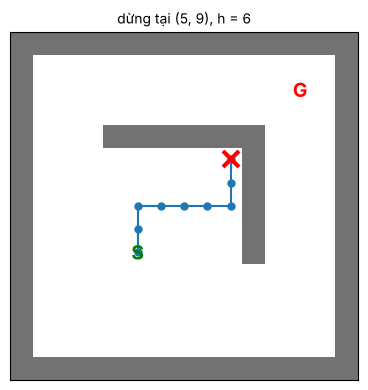

In [12]:
# (b) chọn ngẫu nhiên, 500 lần chạy
np.random.seed(2024)
set_order("NESW", random = True, verbose = False)
stops = [local_search_trace(maze)[-1] for _ in range(500)]
cnt = Counter(stops)
print("Vị trí dừng khi chọn hướng ngẫu nhiên (500 lần):")
for s, c in cnt.most_common(): print(f"  {s}: {c} lần ({c/5:.1f}%), h = {manhattan(s, goal)}")
print("Tới được đích:", sum(1 for s in stops if s == tuple(goal)), "/ 500")

fig, axes = plt.subplots(1, min(3, len(cnt)), figsize=(12, 4)); axes = np.atleast_1d(axes)
np.random.seed(5)
seen = set()
for ax in axes:
    for _ in range(200):
        p = local_search_trace(maze)
        if p[-1] not in seen: seen.add(p[-1]); plot_maze_path(maze, p, ax, f"dừng tại {p[-1]}, h = {manhattan(p[-1], goal)}"); break
plt.tight_layout(); plt.show()
set_order("NESW", verbose = False)   # trả về cấu hình mặc định

**Nhận xét:**

* Với cả 24 thứ tự xét hướng, thuật toán đều dừng ở **cùng một ô (5, 9)** và không có thứ tự nào tới được đích (0/24). Ở chế độ ngẫu nhiên, 500/500 lần cũng dừng ở (5, 9) (0% tới đích).
* Lý do: đổi thứ tự hay xáo trộn ngẫu nhiên chỉ ảnh hưởng đến cách phá hoà khi 2 ô kề có cùng h (ví dụ ở S, đi N hay E đều có h = 13). Nhưng cả hai đường đều bị bức tường chặn và cùng trôi về góc (5, 9), vì ở ô nào cũng có nước giảm h đi dần về phía góc tường.
* Bài học: đổi cách phá hoà **không** giúp thoát local optimum khi bẫy là do hình dạng của hàm mục tiêu. Cần cơ chế khác như Random Restart (bắt đầu từ ô khác, ví dụ phía bên kia bức tường), Simulated Annealing (chấp nhận bước xấu hơn), hoặc dùng tìm kiếm có nhớ đường đi như BFS/A*.

**Note:** Simple hill climbing is greedy. It gets stuck in local optima!

**Kết luận:** Simple Hill Climbing rất rẻ (chỉ nhớ 1 trạng thái, mỗi bước xét tối đa 4 ô kề) nhưng **không đầy đủ** (incomplete): trên mê cung có tường chắn nó dừng ở local optimum (5, 9) với h = 6 và không thể đến G.